# 01b — AOI selection

**Task:** M1-T02 (select and validate AOIs).

**Purpose:** check each candidate area in `config/aoi_candidates.yaml` against the four acceptance criteria (dryland aridity index, enough cloud-free Sentinel-2 dates per year, seasons justified by rainfall, a map) and write the chosen AOIs to `config/aois.geojson`.

**Inputs:** `config/aoi_candidates.yaml`, `config/project.yaml`; CHIRPS v3 rainfall and Hobbins reference ET (open, no account); Sentinel Hub Catalog and Process APIs (credentials in `.env`, quota-limited).

**Outputs:** `config/aois.geojson`; figures `reports/figures/m1_aoi_map.png`, `m1_aoi_climatology.png`, `m1_aoi_availability.png`, `m1_aoi_true_color.png`; tables `reports/results/m1_aoi_climate.csv`, `m1_aoi_availability.csv`, `m1_aoi_summary.csv`.

**Run time:** first run about 5–10 minutes (≈1,500 small remote reads of rainfall/ET files, then the API calls); later runs read the caches in `data/raw/` and take seconds.

**Choosing the final AOIs is the project owner's decision.** This notebook gathers the evidence; set `include: true/false` (or move a centre) in `config/aoi_candidates.yaml` and re-run.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import logging
import platform
import warnings

# tqdm (used by sentinelhub) warns when ipywidgets is absent; progress bars still work as text.
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import rasterio
import sentinelhub
import yaml

import desertification
from desertification.aoi import (
    aoi_feature, aridity_class, aridity_index, availability_by_year, monthly_climatology,
    season_share, season_window, seasons_from_climatology, square_aoi,
)
from desertification.aux_data import monthly_series, rainfall_overview
from desertification.config import get_path, load_config, load_env
from desertification.ingest import fetch_true_color, output_size
from desertification.sh_client import (
    cached_catalog_search, catalog_request_count, missing_credentials, summarize_scenes,
)
from desertification.usage import (
    append_usage, check_cap, estimate_process_pu, latest_balance, make_entry, read_usage_log,
)
from desertification.viz import (
    plot_aoi_map, plot_availability, plot_climatology_panels, plot_image_grid,
)

# WARNING keeps notebook output free of INFO lines with absolute local paths.
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")

cfg = load_config()
SEED = cfg["project"]["seed"]
rng = np.random.default_rng(SEED)
sel = cfg["aoi_selection"]
FIGURES = get_path(cfg, "figures")
RESULTS = get_path(cfg, "results")

print(f"Python {platform.python_version()} | desertification {desertification.__version__} | "
      f"sentinelhub {sentinelhub.__version__} | rasterio {rasterio.__version__} | pandas {pd.__version__}")

Python 3.12.3 | desertification 0.1.0 | sentinelhub 3.12.1 | rasterio 1.5.2 | pandas 3.1.1


## 1. Candidates and their 20 km squares

Each AOI is a square of `box_size_m` (20 km) in the UTM zone of its centre, with bounds snapped to the 100 m cell grid so cells line up exactly with the AOI edge (ROADMAP §4.3). At 20 m that is 1000 × 1000 pixels, below the 2500 × 2500 Process API limit.

In [2]:
with open(get_path(cfg, "aoi_candidates"), encoding="utf-8") as fh:
    candidates = yaml.safe_load(fh)["candidates"]

geoms = {c["aoi_id"]: square_aoi(c["centre_lon"], c["centre_lat"], sel["box_size_m"], sel["snap_m"])
         for c in candidates}
titles = {c["aoi_id"]: c["name"] for c in candidates}
bboxes_wgs84 = {k: g["bbox_wgs84"] for k, g in geoms.items()}

pd.DataFrame([
    {"aoi_id": c["aoi_id"], "name": c["name"], "role": c["role"], "include": c["include"],
     "centre (lat, lon)": (c["centre_lat"], c["centre_lon"]), "utm_epsg": geoms[c["aoi_id"]]["utm_epsg"],
     "bbox_wgs84": [round(v, 3) for v in geoms[c["aoi_id"]]["bbox_wgs84"]]}
    for c in candidates
])

,aoi_id,name,role,include,"centre (lat, lon)",utm_epsg,bbox_wgs84
0,aral,Aral Sea / Aralkum (UZ/KZ),degrading,True,"(45.0, 60.0)",32641,"[59.869, 44.906, 60.132, 45.093]"
1,ferlo,"Ferlo, Senegal (Sahel)",mixed,True,"(15.5, -14.5)",32628,"[-14.594, 15.409, -14.407, 15.591]"
2,fakara,"Fakara / Tillaberi, Niger (Sahel)",mixed,True,"(13.5, 2.6)",32631,"[2.507, 13.41, 2.692, 13.591]"
3,kubuqi,"Kubuqi Desert, Inner Mongolia (CN)",improving_control,True,"(40.2, 108.5)",32649,"[108.379, 40.108, 108.62, 40.293]"
4,urmia,"Lake Urmia basin, Iran",degrading,True,"(37.7, 45.3)",32638,"[45.186, 37.61, 45.413, 37.791]"
5,erg,"Grand Erg Occidental, Algeria (stable erg)",stable_control,True,"(30.6, 0.6)",32631,"[0.493, 30.508, 0.706, 30.692]"


## 2. Aridity and seasons from rainfall climatology

**Why:** the UNCCD defines drylands as areas where annual precipitation divided by potential evapotranspiration (the *aridity index*, AI) is between 0.05 and 0.65 (Convention Art. 1). We compute AI directly from that definition: mean annual CHIRPS v3 rainfall ÷ mean annual Hobbins reference evapotranspiration (ETo), both monthly at 0.05°, averaged over the 1991–2020 climate normal. (The usual Global Aridity Index dataset could not be downloaded automatically; this is the same ratio from open sources.)

**Seasons:** the wet season is the wettest 4 consecutive months of the rainfall climatology and the dry season the driest 4; both are AOI-specific and can wrap the year end.

**Cost:** open data, no account and no Sentinel Hub quota. The first run reads ≈720 remote files (only the few pixels per AOI), then everything is cached.

In [3]:
ALLOW_CLIMATE_DOWNLOADS = True  # open CHC data, no quota; cached after the first run

y0, y1 = sel["climatology_years"]
rain = monthly_series(cfg, "chirps", bboxes_wgs84, y0, y1, allow_download=ALLOW_CLIMATE_DOWNLOADS)
eto = monthly_series(cfg, "eto", bboxes_wgs84, y0, y1, allow_download=ALLOW_CLIMATE_DOWNLOADS)
print("rainfall rows:", None if rain is None else len(rain), "| missing:", None if rain is None else int(rain["value"].isna().sum()))
print("ETo rows:", None if eto is None else len(eto), "| missing:", None if eto is None else int(eto["value"].isna().sum()))

WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1991.07.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1991.03.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1991.01.cog. Retrying again in 2.0 secs


WARNING rasterio._err: CPLE_AppDefined:HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1991.05.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1992.04.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.1992.03.cog. Retrying again in 2.0 secs


... (269 outputs left out)

WARNING rasterio._err: CPLE_AppDefined:HTTP error code: 429 - https://data.chc.ucsb.edu/products/Hobbins_RefET/ETos_p05_monthly_global/tifs/ETos_p05.2017.12.tiff. Retrying again in 2.0 secs


WARNING rasterio._err: CPLE_AppDefined:HTTP error code: 429 - https://data.chc.ucsb.edu/products/Hobbins_RefET/ETos_p05_monthly_global/tifs/ETos_p05.2019.08.tiff. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 429 - https://data.chc.ucsb.edu/products/Hobbins_RefET/ETos_p05_monthly_global/tifs/ETos_p05.2019.10.tiff. Retrying again in 2.0 secs


rainfall rows: 2160 | missing: 6
ETo rows: 2160 | missing: 0


In [4]:
rain_clim = monthly_climatology(rain)
eto_clim = monthly_climatology(eto)

climate_rows, seasons = [], {}
for c in candidates:
    k = c["aoi_id"]
    p_year, et_year = rain_clim.loc[k].sum(), eto_clim.loc[k].sum()
    ai = aridity_index(p_year, et_year)
    wet, dry = seasons_from_climatology(rain_clim.loc[k].values, sel["season_length_months"])
    seasons[k] = {"wet": wet, "dry": dry}
    climate_rows.append({
        "aoi_id": k, "role": c["role"],
        "rain_mm_per_year": round(p_year, 1), "eto_mm_per_year": round(et_year, 1),
        "aridity_index": round(ai, 3), "aridity_class": aridity_class(ai, sel["dryland_ai_range"]),
        "wet_season_months": wet, "dry_season_months": dry,
        "wet_season_rain_share": round(season_share(rain_clim.loc[k].values, wet), 3),
    })
climate = pd.DataFrame(climate_rows)
RESULTS.mkdir(parents=True, exist_ok=True)
climate.to_csv(RESULTS / "m1_aoi_climate.csv", index=False)
climate

,aoi_id,role,rain_mm_per_year,eto_mm_per_year,aridity_index,aridity_class,wet_season_months,dry_season_months,wet_season_rain_share
0,aral,degrading,185.0,1288.1,0.144,dryland,"[12, 1, 2, 3]","[6, 7, 8, 9]",0.446
1,ferlo,mixed,438.9,2565.0,0.171,dryland,"[7, 8, 9, 10]","[1, 2, 3, 4]",0.924
2,fakara,mixed,510.7,2323.0,0.220,dryland,"[6, 7, 8, 9]","[11, 12, 1, 2]",0.930
3,kubuqi,improving_control,291.7,1239.3,0.235,dryland,"[6, 7, 8, 9]","[11, 12, 1, 2]",0.756
4,urmia,degrading,269.3,1404.1,0.192,dryland,"[2, 3, 4, 5]","[6, 7, 8, 9]",0.543
5,erg,stable_control,91.7,2150.6,0.043,hyper-arid,"[1, 2, 3, 4]","[5, 6, 7, 8]",0.461


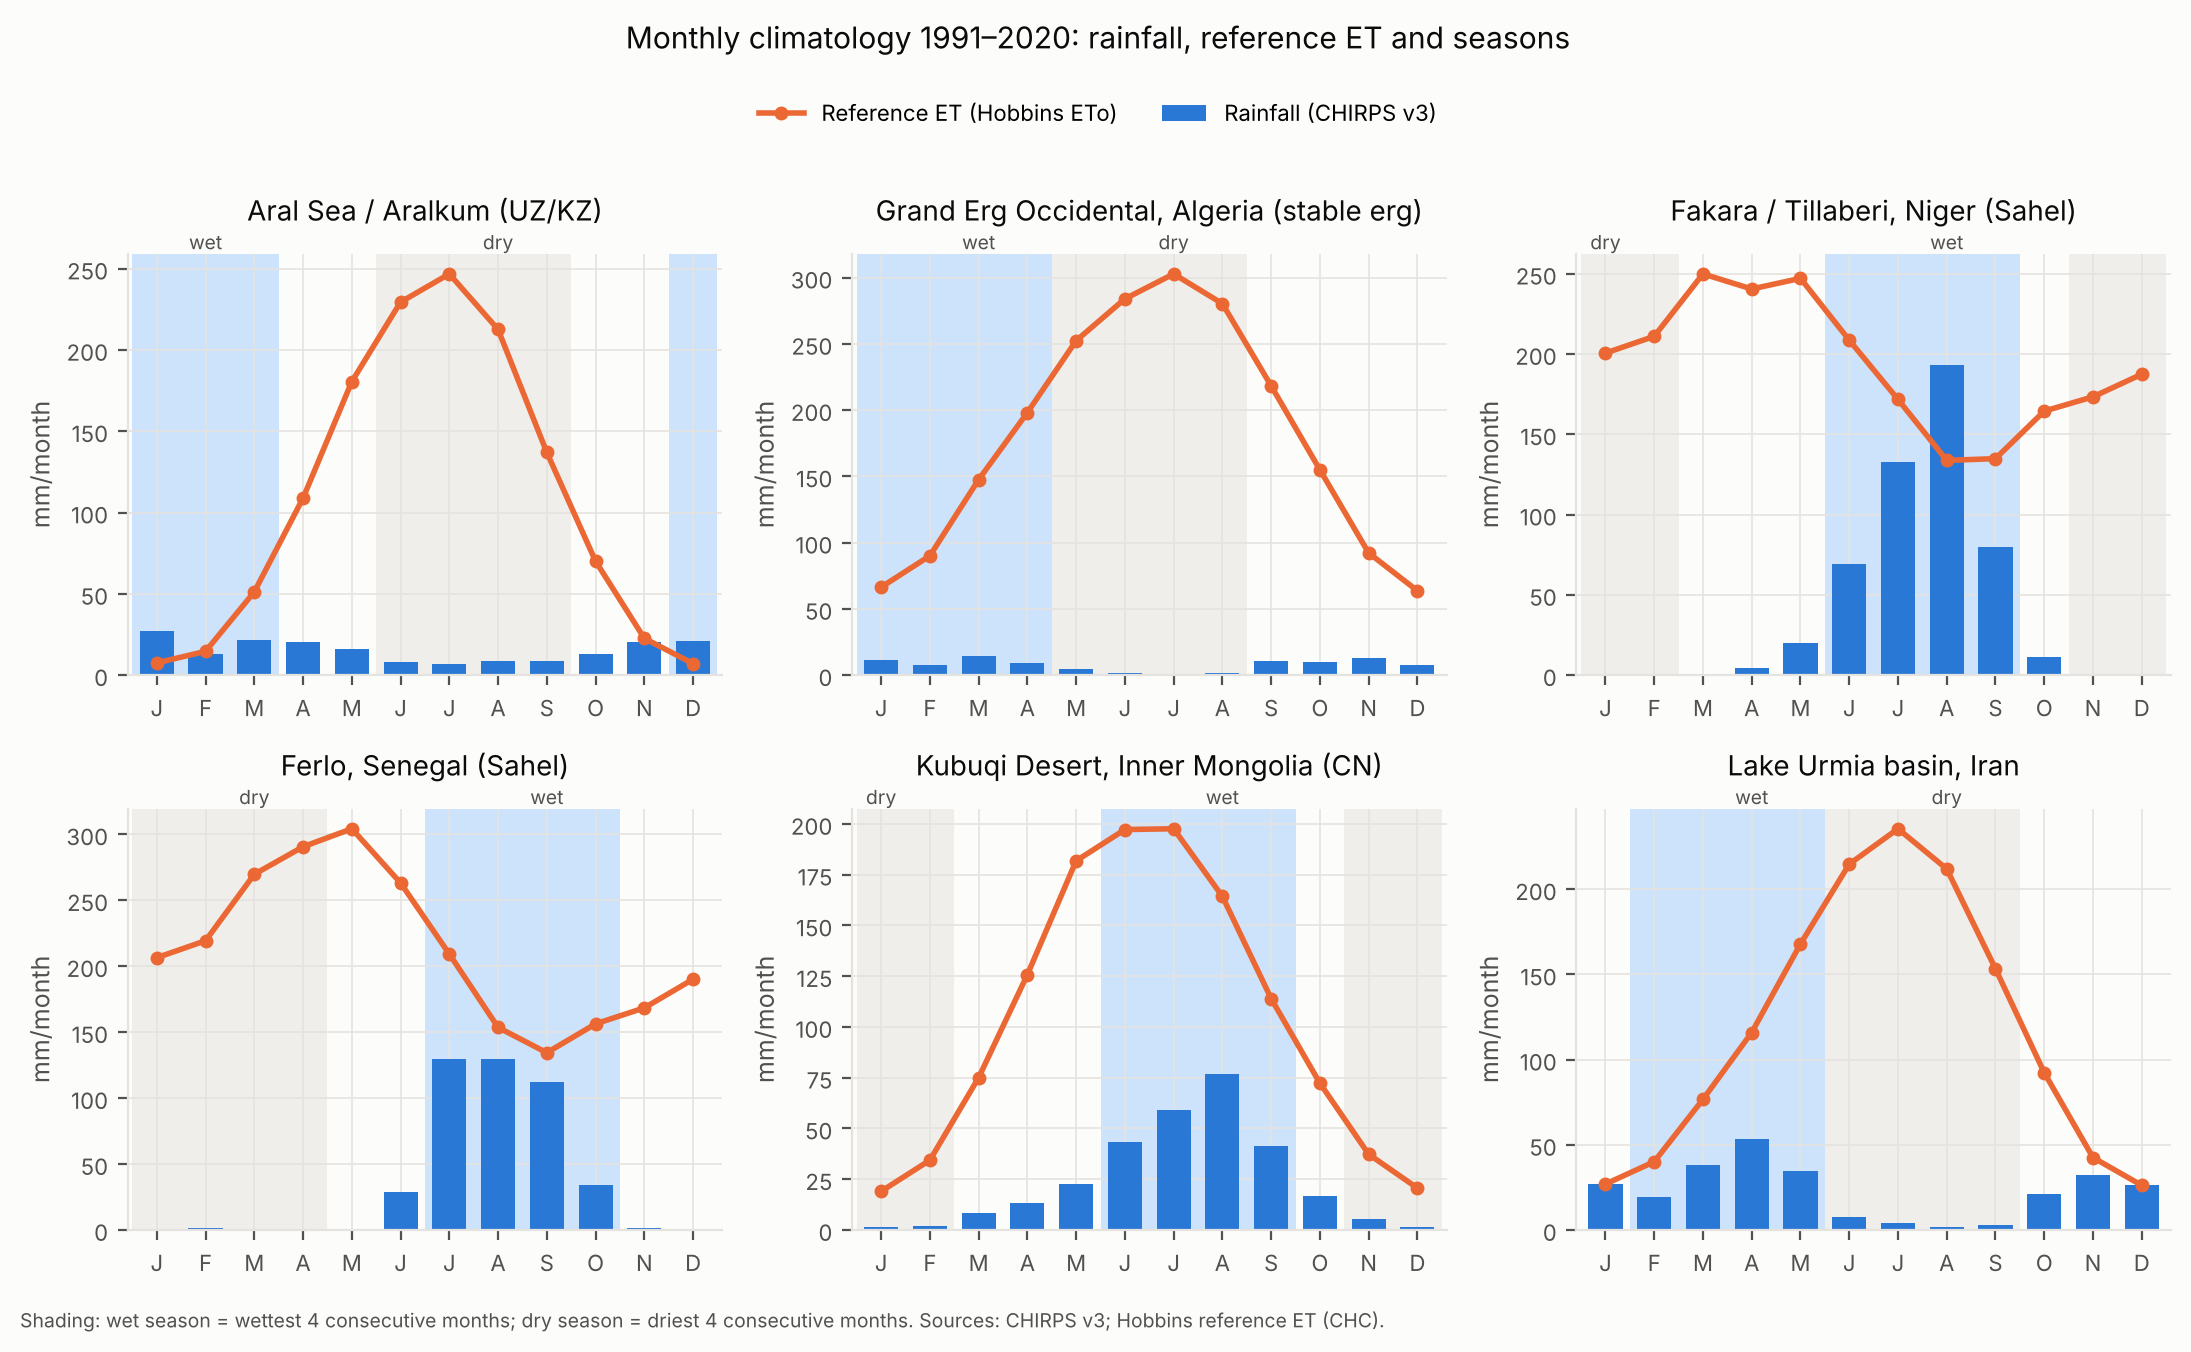

In [5]:
fig = plot_climatology_panels(rain_clim, eto_clim, seasons, titles, f"{y0}–{y1}",
                              out_path=FIGURES / "m1_aoi_climatology.png")

## 3. Map

AOI centres over mean annual rainfall for the study years (CHIRPS v3, read at reduced resolution from the files' built-in overviews).

WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 0 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.2019.02.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 0 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.2019.08.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 0 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.2019.07.cog. Retrying again in 2.0 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 0 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.2019.08.cog. Retrying again in 4.8 secs


WARNING rasterio._env: CPLE_AppDefined in HTTP error code: 0 - https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/global/cogs/chirps-v3.0.2019.08.cog. Retrying again in 9.8 secs


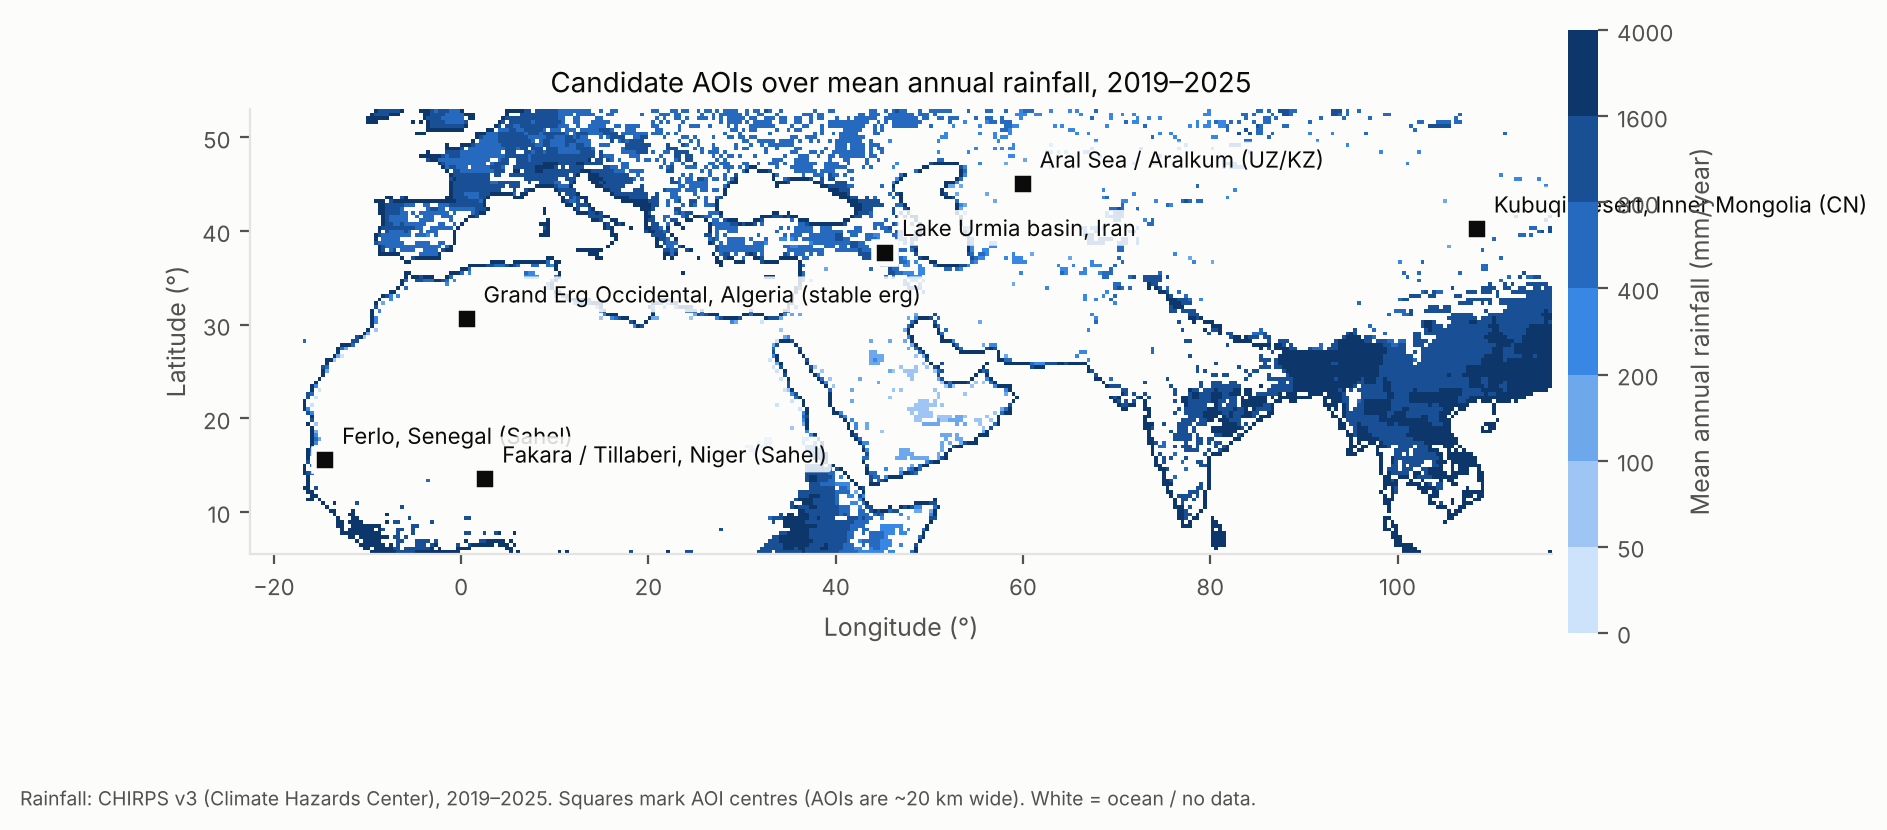

In [6]:
lons = [c["centre_lon"] for c in candidates]
lats = [c["centre_lat"] for c in candidates]
pad = 8
map_bounds = [min(lons) - pad, max(min(lats) - pad, -59), max(lons) + pad, min(max(lats) + pad, 59)]
m0, m1 = sel["map_years"]
overview = rainfall_overview(cfg, map_bounds, m0, m1, decimation=8, allow_download=ALLOW_CLIMATE_DOWNLOADS)
if overview is not None:
    rain_map, extent = overview
    fig = plot_aoi_map(rain_map, extent,
                       [{"aoi_id": c["aoi_id"], "name": c["name"], "lon": c["centre_lon"], "lat": c["centre_lat"]}
                        for c in candidates],
                       f"{m0}–{m1}", out_path=FIGURES / "m1_aoi_map.png")

## 4. Sentinel-2 availability (Catalog API — needs credentials)

**Why:** composites and trends need enough cloud-free looks per year. We count distinct acquisition dates per year and call a date *usable* if at least one Sentinel-2 L2A product covering the AOI that day has tile cloud cover ≤ `usable_cloud_pct` (40 %). Target: ≥ 20 usable dates per year (ROADMAP M1-T02).

**Cost:** one Catalog request per 100 products returned, 0 PU (measured in P0-T03, Decision log #22). The cell below prints the plan before anything is sent. Set `ALLOW_API_CALLS = True` only after the request count has been approved.

In [7]:
ALLOW_API_CALLS = False

load_env(cfg)
missing = missing_credentials()
years = list(range(int(cfg["periods"]["study"]["start"][:4]), int(cfg["periods"]["study"]["end"][:4]) + 1))
n_searches = len(candidates) * len(years)
print("Credentials present:", not missing)
print(f"Catalog plan: {len(candidates)} AOIs x {len(years)} years = {n_searches} searches, "
      f"at least {n_searches} requests (about 1 extra per 100 products), 0 PU")

availability_parts, catalog_requests = [], 0
for c in candidates:
    k = c["aoi_id"]
    for year in years:
        feats, _, called = cached_catalog_search(
            cfg, name=f"{k}_{year}", bbox_wgs84=geoms[k]["bbox_wgs84"],
            start=f"{year}-01-01", end=f"{year}-12-31",
            allow_api=ALLOW_API_CALLS and not missing,
        )
        if called:
            catalog_requests += catalog_request_count(len(feats))
        if feats is not None:
            part = availability_by_year(summarize_scenes(feats), sel["usable_cloud_pct"])
            part.insert(0, "aoi_id", k)
            availability_parts.append(part)

availability = pd.concat(availability_parts, ignore_index=True) if availability_parts else pd.DataFrame()
print(f"Catalog requests made in this run: {catalog_requests}")
if not availability.empty:
    availability.to_csv(RESULTS / "m1_aoi_availability.csv", index=False)
    fig = plot_availability(availability, sel["min_usable_dates_per_year"], titles,
                            out_path=FIGURES / "m1_aoi_availability.png")
availability

Credentials present: False
Catalog plan: 6 AOIs x 7 years = 42 searches, at least 42 requests (about 1 extra per 100 products), 0 PU
Catalog requests made in this run: 0


""


## 5. True-colour check (Process API — needs credentials)

**Why:** confirm that each square shows the landscape we expect (exposed seabed, rangeland, cropland, dunes, lake shore) before committing quota to it. One least-cloudy image per AOI in the dry season of the first and last study year, at 60 m. This is for looking only; analysis uses 20 m data later.

In [8]:
size = output_size(geoms[candidates[0]["aoi_id"]]["bbox_utm"], sel["true_color_resolution_m"])
pu_each = estimate_process_pu(*size, n_input_bands=3)
first_year, last_year = years[0], years[-1]
n_images = len(candidates) * 2
usage_rows = read_usage_log(get_path(cfg, "api_usage_log"))
fits, left = check_cap(usage_rows, "setup_pilot", n_images * pu_each, cfg["quota"]["pu_caps"])
print(f"True-colour plan: {n_images} requests x ~{pu_each:.2f} PU = ~{n_images * pu_each:.1f} PU "
      f"(fits setup_pilot cap: {fits}, PU left in that cap afterwards: {left:.0f})")

images, tc_requests = {}, 0
for c in candidates:
    k = c["aoi_id"]
    images[k] = {}
    for year in (first_year, last_year):
        start, end = season_window(seasons[k]["dry"], year)
        img, _, called = fetch_true_color(cfg, k, geoms[k]["bbox_utm"], geoms[k]["utm_epsg"], start, end,
                                          allow_api=ALLOW_API_CALLS and not missing and fits)
        tc_requests += int(called)
        images[k][f"Dry season {year}"] = img
print(f"Process requests made in this run: {tc_requests}")
if any(v is not None for d in images.values() for v in d.values()):
    fig = plot_image_grid(images, titles, f"{first_year}, {last_year}",
                          out_path=FIGURES / "m1_aoi_true_color.png")

True-colour plan: 12 requests x ~0.42 PU = ~5.1 PU (fits setup_pilot cap: True, PU left in that cap afterwards: 995)
Process requests made in this run: 0


### Quota ledger

If this run made API calls, record them. Copy the balances from the [CDSE dashboard](https://shapps.dataspace.copernicus.eu/dashboard/) before and after the run (leave `None` if unknown and fill in the CSV later).

In [9]:
PU_BEFORE, PU_AFTER = None, None
REQUESTS_BEFORE, REQUESTS_AFTER = None, None

log_path = get_path(cfg, "api_usage_log")
if catalog_requests or tc_requests:
    append_usage(log_path, make_entry(
        task_id="M1-T02", api="catalog+process", budget_category="setup_pilot",
        request_count=catalog_requests + tc_requests + 1,  # +1 OAuth token
        purpose=f"AOI selection: {catalog_requests} Catalog page(s), {tc_requests} true-colour image(s)",
        pu_before=PU_BEFORE, pu_after=PU_AFTER,
        requests_before=REQUESTS_BEFORE, requests_after=REQUESTS_AFTER,
    ))
    print("Logged this run in", log_path.relative_to(cfg["_root"]))
else:
    print("No API calls in this run, so nothing new to log.")
print("Latest recorded balance:", latest_balance(read_usage_log(log_path)))

No API calls in this run, so nothing new to log.
Latest recorded balance: {'pu': 30000.0, 'requests': 29999.0}


## 6. Summary and `config/aois.geojson`

An AOI passes when it is a dryland by the UNCCD range **or** is explicitly a control, and when every study year reaches the usable-date target (unknown until the Catalog section has run). Only candidates with `include: true` are written.

In [10]:
min_usable = (availability.groupby("aoi_id")["n_usable_dates"].min()
              if not availability.empty else pd.Series(dtype=float))
summary_rows, features = [], []
for c, row in zip(candidates, climate_rows):
    k = c["aoi_id"]
    is_control = c["role"].endswith("control")
    dryland_ok = row["aridity_class"] == "dryland" or is_control
    mu = int(min_usable[k]) if k in min_usable.index else None
    availability_ok = None if mu is None else mu >= sel["min_usable_dates_per_year"]
    summary_rows.append({
        "aoi_id": k, "include": c["include"], "role": c["role"], "aridity_index": row["aridity_index"],
        "aridity_class": row["aridity_class"], "dryland_or_control": dryland_ok,
        "min_usable_dates_per_year": mu, "availability_ok": availability_ok,
        "wet_season_months": row["wet_season_months"], "dry_season_months": row["dry_season_months"],
    })
    if c["include"]:
        features.append(aoi_feature(
            c, geoms[k],
            aridity_index=row["aridity_index"], aridity_class=row["aridity_class"],
            aridity_source=f"CHIRPS v3 / Hobbins ETo, {y0}-{y1}",
            wet_season_months=row["wet_season_months"], dry_season_months=row["dry_season_months"],
            min_usable_dates_per_year=mu,
        ))
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "m1_aoi_summary.csv", index=False)

aois_path = get_path(cfg, "aois")
collection = {
    "type": "FeatureCollection", "name": "aois",
    "description": "Study AOIs selected in M1-T02 (notebooks/01b_aoi_selection.ipynb). Polygons are the UTM squares in WGS84; bbox_utm/utm_epsg are authoritative for requests.",
    "features": features,
}
aois_path.write_text(json.dumps(collection, indent=2) + "\n", encoding="utf-8")
print(f"Wrote {len(features)} AOIs to {aois_path.relative_to(cfg['_root'])}")
summary

Wrote 6 AOIs to config/aois.geojson


,aoi_id,include,role,aridity_index,aridity_class,dryland_or_control,min_usable_dates_per_year,availability_ok,wet_season_months,dry_season_months
0,aral,True,degrading,0.144,dryland,True,None,None,"[12, 1, 2, 3]","[6, 7, 8, 9]"
1,ferlo,True,mixed,0.171,dryland,True,None,None,"[7, 8, 9, 10]","[1, 2, 3, 4]"
2,fakara,True,mixed,0.220,dryland,True,None,None,"[6, 7, 8, 9]","[11, 12, 1, 2]"
3,kubuqi,True,improving_control,0.235,dryland,True,None,None,"[6, 7, 8, 9]","[11, 12, 1, 2]"
4,urmia,True,degrading,0.192,dryland,True,None,None,"[2, 3, 4, 5]","[6, 7, 8, 9]"
5,erg,True,stable_control,0.043,hyper-arid,True,None,None,"[1, 2, 3, 4]","[5, 6, 7, 8]"


### What to check

- **Aridity:** every AOI is a dryland (AI 0.05–0.65) or explicitly a control (`role` ending in `control`).
- **Availability:** `min_usable_dates_per_year` ≥ 20 for every year, or a documented exception.
- **Seasons:** the climatology figure shows a clear wet season for the Sahel and Kubuqi AOIs; where rainfall is almost aseasonal (e.g. very arid sites) the season split matters less and is noted.
- **Imagery:** each true-colour square shows the expected landscape; move a centre in `config/aoi_candidates.yaml` if not.